# Влияние потребления кофе на показатели сна и здоровья

**Выполнила:** Гаургашвили М.А.

**Группа:** 244

In [ ]:
import pandas as pd
df=pd.read_csv('synthetic_coffee_health_10000.csv')
df.head()

,ID,Age,Gender,Country,Coffee_Intake,Caffeine_mg,Sleep_Hours,Sleep_Quality,BMI,Heart_Rate,Stress_Level,Physical_Activity_Hours,Health_Issues,Occupation,Smoking,Alcohol_Consumption
0,1,40,Male,Germany,3.5,328.1,7.5,Good,24.9,78,Low,14.5,NaN,Other,0,0
1,2,33,Male,Germany,1.0,94.1,6.2,Good,20.0,67,Low,11.0,NaN,Service,0,0
2,3,42,Male,Brazil,5.3,503.7,5.9,Fair,22.7,59,Medium,11.2,Mild,Office,0,0
3,4,53,Male,Germany,2.6,249.2,7.3,Good,24.7,71,Low,6.6,Mild,Other,0,0
4,5,32,Female,Spain,3.1,298.0,5.3,Fair,24.1,76,Medium,8.5,Mild,Student,0,1


In [ ]:
df.shape

(10000, 16)

##  Описание данных

Датасет посвящён исследованию влияния потребления кофе и кофеина на показатели здоровья и образ жизни человека.  
В данных представлены демографические характеристики, уровень потребления кофе, показатели сна, физической активности, уровня стресса и другие факторы, связанные со здоровьем.

---

**Один человек — это одно наблюдение.**
  

Всего в датасете содержится **10 000 наблюдений** по **16 признакам**.

---

Ссылка на источник: https://www.kaggle.com/datasets/uom190346a/global-coffee-health-dataset

In [ ]:
df=df.astype({'Smoking':'boolean', 'Alcohol_Consumption':'boolean'})

In [ ]:
df.dtypes

,0
ID,int64
Age,int64
Gender,object
Country,object
Coffee_Intake,float64
Caffeine_mg,float64
Sleep_Hours,float64
Sleep_Quality,object
BMI,float64
Heart_Rate,int64


## Описание признаков

| Название признака | Описание | Тип признака | Формат данных |
|:-------------------|:-----------------------------------------|:---------------------------|:------------------------|
| **ID** | Уникальный идентификатор респондента | Количественный (дискретный) | int64 |
| **Age** | Возраст респондента (полных лет) | Количественный (непрерывный) | int64 |
| **Gender** | Пол респондента (Male/Female/Other) | Категориальный (номинальный, бинарный) | object |
| **Country** | Страна проживания | Категориальный (номинальный) | object |
| **Coffee_Intake** | Среднесуточное потребление кофе (в чашках) | Количественный (непрерывный) | float64 |
| **Caffeine_mg** | Среднесуточное потребление кофеина (в мг) | Количественный (непрерывный) | float64 |
| **Sleep_Hours** | Средняя продолжительность сна (в часах) | Количественный (непрерывный) | float64 |
| **Sleep_Quality** | Субъективная оценка качества сна (Good/Fair/Poor/Excellent) | Категориальный (порядковый) | object |
| **BMI** | Индекс массы тела (кг/м²) | Количественный (непрерывный) | float64 |
| **Heart_Rate** | Частота сердечных сокращений в покое (уд/мин) | Количественный (дискретный) | int64 |
| **Stress_Level** | Уровень стресса на основе часов сна и образа жизни (Low, Medium, High) | Категориальный (порядковый) | object |
| **Physical_Activity_Hours** | Часы физической активности в неделю | Количественный (непрерывный) | float64 |
| **Health_Issues** | Степень проблем со здоровьем на основе возраста, сна и массы тела (None, Mild, Moderate, Severe) | Категориальный (порядковый) | object |
| **Occupation** | Род деятельности (Office, Healthcare, Student, Service, Other) | Категориальный (номинальный) | object |
| **Smoking** | Курящий или нет | Категориальный (бинарный) | boolean |
| **Alcohol_Consumption** | Употребляет алкоголь или нет | Категориальный (бинарный) | boolean |


## Пропуски и дубликаты

In [ ]:
df.isna().sum()

,0
ID,0
Age,0
Gender,0
Country,0
Coffee_Intake,0
Caffeine_mg,0
Sleep_Hours,0
Sleep_Quality,0
BMI,0
Heart_Rate,0


Так как в столбце признака Health_Issues пропусков больше чем 40%, столбец нужно удалить, мы не будем его использовать

In [ ]:
df = df.drop('Health_Issues', axis=1)

In [ ]:
df.duplicated().sum()

np.int64(0)

Сохраним датафрейм в новую переменную df_clean с очищенными данными

In [ ]:
df_clean = df.drop_duplicates()

## Выбросы

ID не включаем в col_num, так как это технический идентификатор.
Coffee_Intake и Caffeine_mg вместе не используем (мультиколлинеарность) — оставим Caffeine_mg

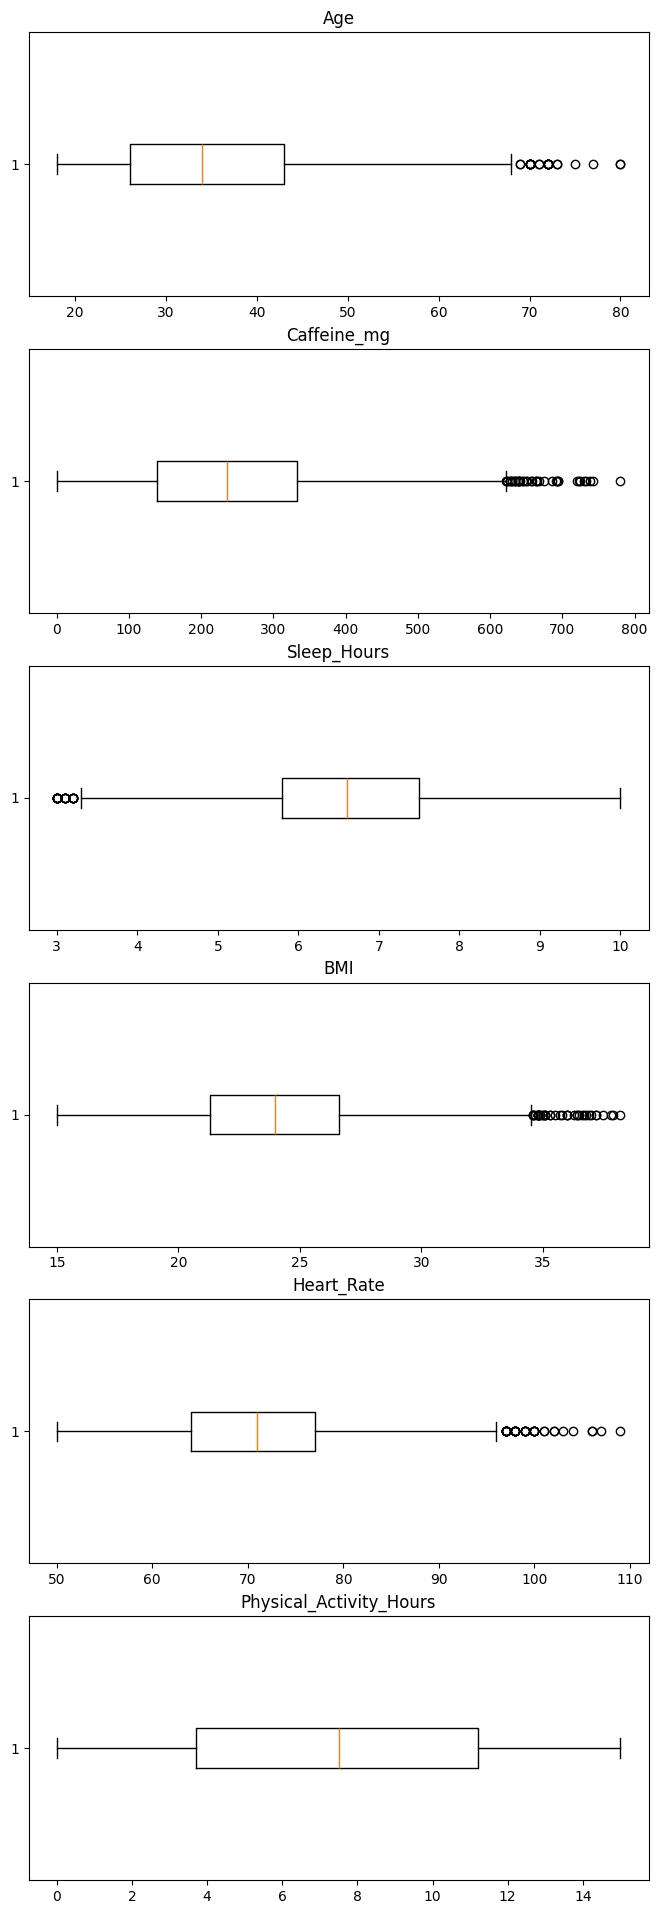

In [ ]:
import matplotlib.pyplot as plt
df_clean = df_clean.drop('Coffee_Intake', axis=1)
col_num = ['Age', 'Caffeine_mg', 'Sleep_Hours', 'BMI', 'Heart_Rate', 'Physical_Activity_Hours'] #создаем список с количественными признаками
fig, ax = plt.subplots(len(col_num), 1, figsize=(8, 4*len(col_num)))  # создаем сетку графиков:
                                                                      # len(col_num) строк и 1 столбец
                                                                      # figsize задает размер всей фигуры (ширина = 8, высота = 4 * количество признаков)

for i in range(len(col_num)):                                         # запускаем цикл по индексам списка признаков
    ax[i].set_title(col_num[i])                                       # добавляем заголовок к каждому графику
    ax[i].boxplot(df_clean[col_num[i]], vert=False)

Делим признаки на две группы:
- std_cols чистим методом 2*std
- iqr_cols чистим методом 1.5*IQR

In [ ]:
std_cols = ['Sleep_Hours', 'BMI', 'Heart_Rate']                #для признаков с распределением близким к нормальному
iqr_cols = ['Age', 'Caffeine_mg', 'Physical_Activity_Hours']   #для асимметричных/равномерных распределений

df_outliers_clean = df_clean.copy() #итоговый датафрейм без выбросов
for col in std_cols:
    avg = df_outliers_clean[col].mean()
    std = df_outliers_clean[col].std()

    left = avg - 2 * std
    right = avg + 2 * std

    df_outliers_clean = df_outliers_clean[df_outliers_clean[col].between(left, right)]

for col in iqr_cols:
    Q1 = df_outliers_clean[col].quantile(0.25)
    Q3 = df_outliers_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    left = Q1 - 1.5 * IQR
    right = Q3 + 1.5 * IQR

    df_outliers_clean = df_outliers_clean[df_outliers_clean[col].between(left, right)]

df_outliers_clean.shape

(8634, 14)

Далее работаем с df_outliers_clean

## Визуализация

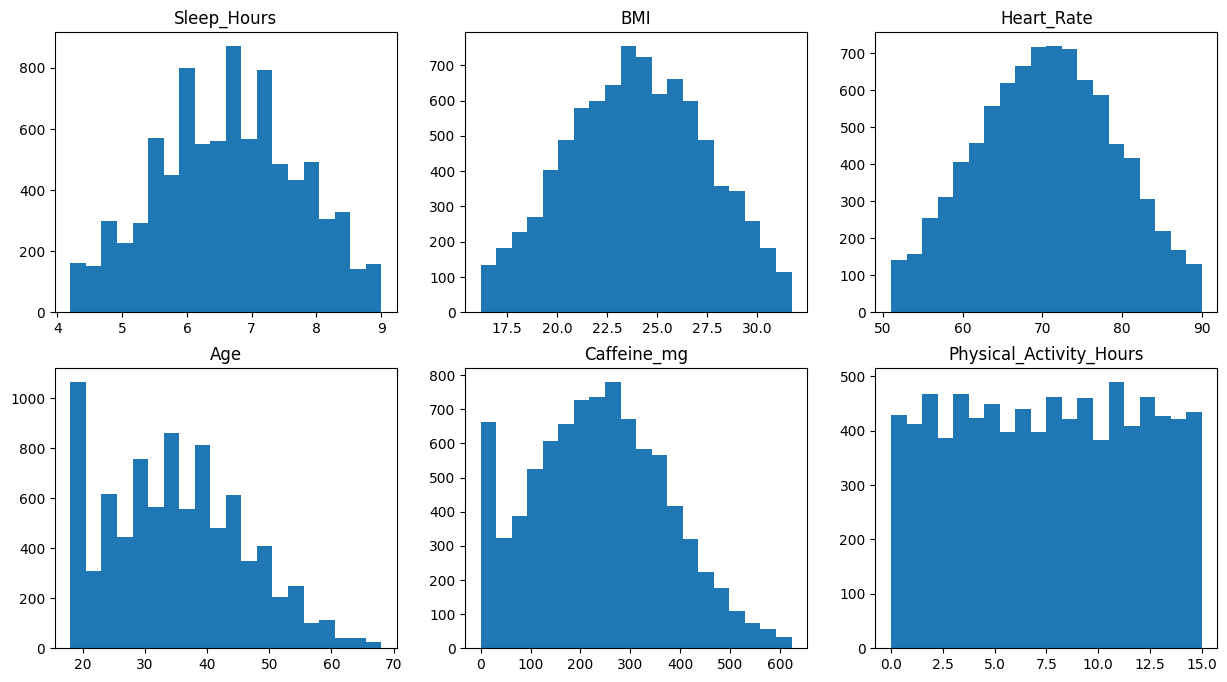

In [ ]:
col_num = ['Sleep_Hours', 'BMI', 'Heart_Rate', 'Age', 'Caffeine_mg', 'Physical_Activity_Hours']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))               # Создаём сетку 2 строки × 3 столбца
axes = axes.flatten()                                         # Превращаем двумерный массив осей в плоский список, чтобы удобно было обращаться по одному индексу в цикле

for i in range(len(col_num)):
    title = col_num[i]                                          # Получаем название признака по индексу
    axes[i].hist(df_outliers_clean[title], bins=20)
    axes[i].set_title(title)



## Выводы по распределению количественных признаков


*   **Age:**
    *   **Форма распределения:** правосторонняя ассиметрия
    *   **Обоснование:** пик распределения приходится на возраст до 20 лет, «хвост» тянется к возрасту 70 лет. Это свидетельствует о том, что в нашем датасете преобладают молодые респонденты.

*   **Caffeine_mg:**
    *   **Форма распределения:** бимодальная правосторонняя асимметрия.
    *   **Обоснование:** первый, самый высокий пик приходится на значение 0 мг и соответствует респондентам, совсем не употребляющим кофеин (около 690 человек). Второй, менее выраженный пик находится в районе 270 мг, что условно соответствует трем чашкам кофе. После 400 мг наблюдается длинный "правый хвост", что указывает на наличие небольшой группы людей с экстремально высоким потреблением кофеина.

*   **Physical_Activity_Hours:**
    *   **Форма распределения:** равномерное распределение
    *   **Обоснование:** все значения от 0 до 14 часов встречаются примерно с одинаковой частотой, без явных пиков и провалов

*   **Sleep_Hours:**
    *   **Форма распределения:** симметричное (близкое к нормальному)
    *   **Обоснование:** Ярко выраженный пик в области 6.8 часов, убывание к краям

*   **BMI:**
    *   **Форма распределения:** близко к нормальному
    *   **Обоснование:** пик в центре (25–26), частота убывает к краям

*   **Heart_Rate:**
    *   **Форма распределения:** симметричное (близкое к нормальному)
    *   **Обоснование:** Один широкий пик в области 70–75 уд/мин, частота убывает к краям



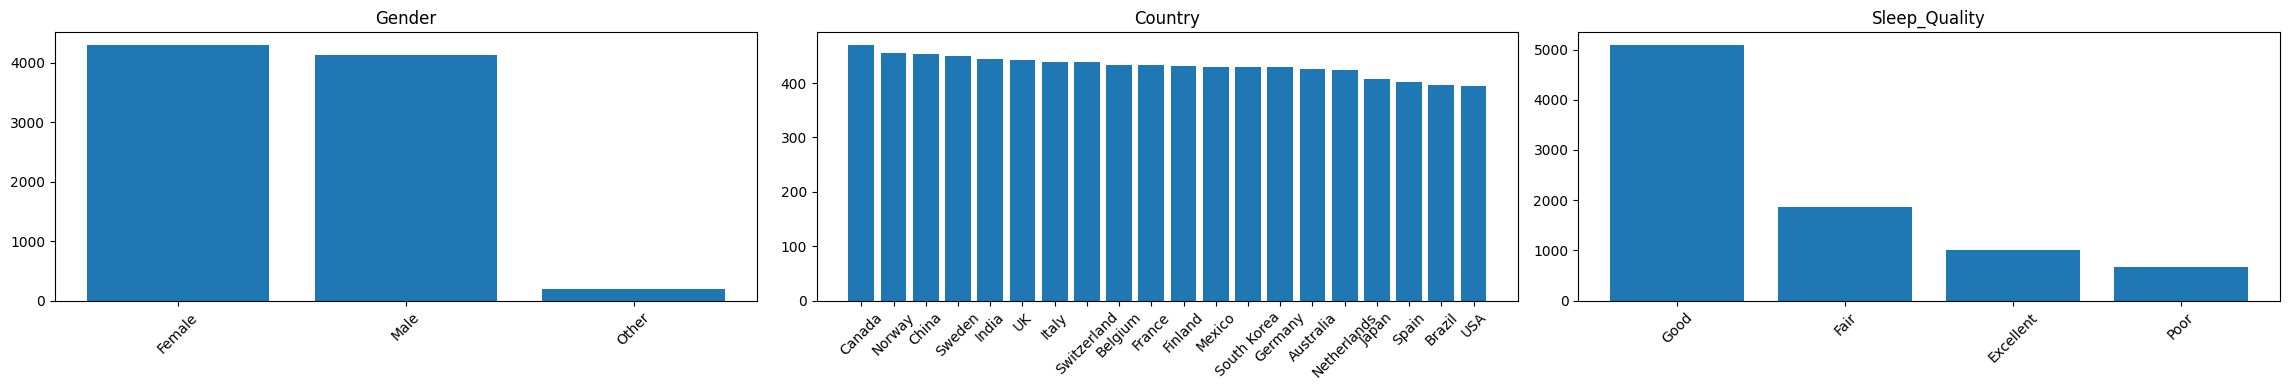

In [ ]:
import matplotlib.pyplot as plt
col_cat = ['Gender', 'Country', 'Sleep_Quality']
fig, ax = plt.subplots(1, 3, figsize=(23, 4))
for i in range(len(col_cat)):
  ax[i].set_title(col_cat[i])
  freq = df_outliers_clean[col_cat[i]].value_counts()
  ax[i].bar(freq.index, freq.values)
  ax[i].tick_params(axis='x', rotation=45)  # Настраиваем подписи на оси х.
                                            # обращаемся к i-тому графику и применяем метод .tick_params() для
                                            # настройки отображения делений и подписей оси х. Поворачиваем подписи на
                                            # 45 градусов

  plt.tight_layout()  # применяем функцию .tight_layout() для автоматической настройки отступов
                      # между графиками, а также элементами графиков, чтобы элементы не
                      # накладывались друг на друга

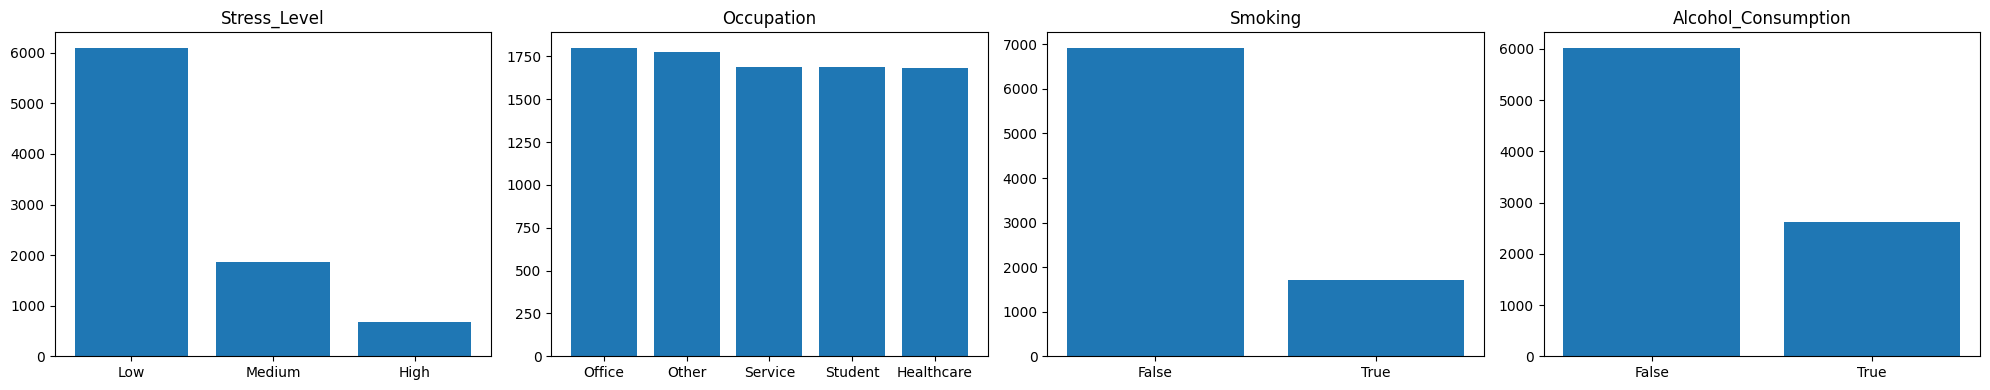

In [ ]:
import matplotlib.pyplot as plt
col_cat = ['Stress_Level', 'Occupation', 'Smoking', 'Alcohol_Consumption']
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for i in range(len(col_cat)):
  ax[i].set_title(col_cat[i])
  freq = df_outliers_clean[col_cat[i]].value_counts()
  ax[i].bar(freq.index.astype(str), freq.values)
  plt.tight_layout()   # применяем функцию .tight_layout() для автоматической настройки отступов
                       # между графиками, а также элементами графиков, чтобы элементы не
                       # накладывались друг на друга

## Выводы по распределению категориальных признаков



*   **Gender:**
доля мужчин и женщин в данных примерно одинаковая, а также присутствует небольшая группа Other

*  **Country:**
распределение по странам сбалансировано, без выраженного преобладания данных одной категории

*   **Sleep_Quality:**
людей с хорошим качеством сна значительно больше, чем тех, кто страдает от проблем со сном. Однако количество людей с плохим, приемлемым и отличным качеством сна не сильно отличается, но значительно уступает показателю хорошего качества

*   **Stress_Level:**
количество людей с низким уровнем стресса в данных значительно преобладает над количеством людей со средним и высоким уровнем стресса

*   **Occupation:**
В данных представлено примерно равное количество людей различных профессий, преобладания какой-либо из профессий не наблюдается

*   **Smoking_True:**
Курильщиков в данных значительно меньше, чем тех, кто не курит

*  **Alcohol_Consumption_True:**
Употребляющих алкоголь более чем вдвое меньше, чем тех, что не употребляет












## Перекодирование данных

Перекодируем данные, так как исходный датасет содержал категориальные признаки в текстовом виде, что делало невозможным расчет корреляций с целевым признаком `Sleep_Hours`.

In [ ]:
df_outliers_clean = pd.get_dummies(df_outliers_clean, columns = ['Smoking', 'Alcohol_Consumption'], dtype='int')     # перекодирование категориальных бинарных признаков
df_outliers_clean.head()

,ID,Age,Gender,Country,Caffeine_mg,Sleep_Hours,Sleep_Quality,BMI,Heart_Rate,Stress_Level,Physical_Activity_Hours,Occupation,Smoking_False,Smoking_True,Alcohol_Consumption_False,Alcohol_Consumption_True
0,1,40,Male,Germany,328.1,7.5,Good,24.9,78,Low,14.5,Other,1,0,1,0
1,2,33,Male,Germany,94.1,6.2,Good,20.0,67,Low,11.0,Service,1,0,1,0
2,3,42,Male,Brazil,503.7,5.9,Fair,22.7,59,Medium,11.2,Office,1,0,1,0
3,4,53,Male,Germany,249.2,7.3,Good,24.7,71,Low,6.6,Other,1,0,1,0
4,5,32,Female,Spain,298.0,5.3,Fair,24.1,76,Medium,8.5,Student,1,0,0,1


In [ ]:
from sklearn.preprocessing import LabelEncoder     # Перекодирование категориальных номинальных и порядковых признаков

custom_order={'Sleep_Quality': {'Poor': 1, 'Fair': 2, 'Good': 3, 'Excellent': 4}, # Ручное кодирование порядковых признаков для сохранения естественного порядка категорий
              'Stress_Level': {'Low': 3, 'Medium': 2, 'High': 1}}                 # Оно позволяет корректно интерпретировать знак корреляции с целевой переменной
lst=['Gender', 'Country', 'Sleep_Quality', 'Stress_Level', 'Occupation']

for col in lst:
  if col in custom_order:         # Если это порядковый признак с заданным порядком
    df_outliers_clean[f'{col}_encoded'] = df_outliers_clean[col].map(custom_order[col]) # Используем map() вместо LabelEncoder, чтобы гарантировать правильную порядковую шкалу и избежать автоматического алфавитного упорядочивания
  else:
    df_outliers_clean[f'{col}_encoded'] = LabelEncoder().fit_transform(df_outliers_clean[col]) # Для номинальных признаков используем LabelEncoder, так как порядок категорий не важен

df_outliers_clean.head()


,ID,Age,Gender,Country,Caffeine_mg,Sleep_Hours,Sleep_Quality,BMI,Heart_Rate,Stress_Level,...,Occupation,Smoking_False,Smoking_True,Alcohol_Consumption_False,Alcohol_Consumption_True,Gender_encoded,Country_encoded,Sleep_Quality_encoded,Stress_Level_encoded,Occupation_encoded
0,1,40,Male,Germany,328.1,7.5,Good,24.9,78,Low,...,Other,1,0,1,0,1,7,3,3,2
1,2,33,Male,Germany,94.1,6.2,Good,20.0,67,Low,...,Service,1,0,1,0,1,7,3,3,3
2,3,42,Male,Brazil,503.7,5.9,Fair,22.7,59,Medium,...,Office,1,0,1,0,1,2,2,2,1
3,4,53,Male,Germany,249.2,7.3,Good,24.7,71,Low,...,Other,1,0,1,0,1,7,3,3,2
4,5,32,Female,Spain,298.0,5.3,Fair,24.1,76,Medium,...,Student,1,0,0,1,0,15,2,2,4


<Axes: >

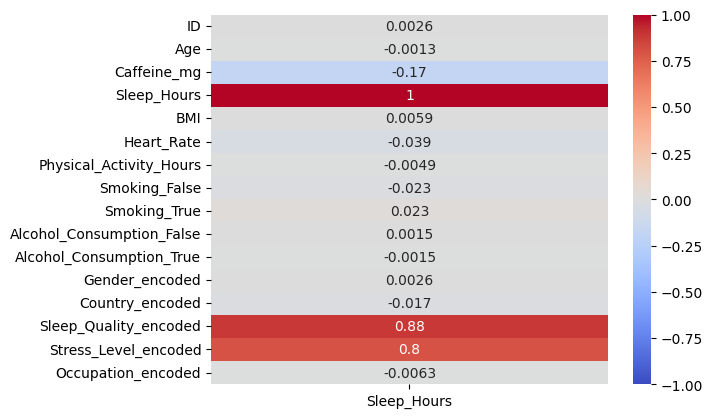

In [ ]:
import seaborn as sns


corr_with_exam = df_outliers_clean.corr(method='spearman', numeric_only=True)[['Sleep_Hours']]
sns.heatmap(corr_with_exam, annot=True, vmin=-1, vmax=1, cmap='coolwarm')

Корреляционный анализ помог нам определить, какие признаки действительно влияют на продолжительность сна (`Sleep_Hours`). Мы использовали коэффициент корреляции Спирмана, так как он подходит для порядковых переменных и не требует нормального распределения данных.

**Результат:** мы выбрали признаки с наиболее выраженной связью:
- `Stress_Level` (корреляция 0.8) — наблюдается сильная положительная связь. Из-за особенностей кодировки (Low = 3, Medium = 2, High = 1) более низкие числовые значения соответствуют более высокому уровню стресса. Таким образом, более высокий уровень стресса чаще сопровождается меньшей продолжительностью сна.
- `Sleep_Quality` (корреляция 0.88) — наблюдается сильная положительная связь: более высокая субъективная оценка сна чаще сопровождается большей продолжительностью сна.
- `Caffeine_mg` (корреляция -0.17) — наблюдается слабая отрицательная связь: большее среднесуточное потребление кофеина чаще сопровождается меньшей продолжительностью сна.
- `Heart_Rate` (корреляция -0.039) — даже слабая, но устойчивая отрицательная связь (больше кофеина/стресса → выше пульс → меньше сна) имеет физиологический смысл, потому что во время глубокого сна пульс замедляется, а высокий пульс может быть маркером стресса или перевозбуждения нервной системы.

Именно эти признаки мы визуализировали на скрипичных графиках, чтобы наглядно показать характер зависимости.

## Скрипичные графики

**Количественные признаки**

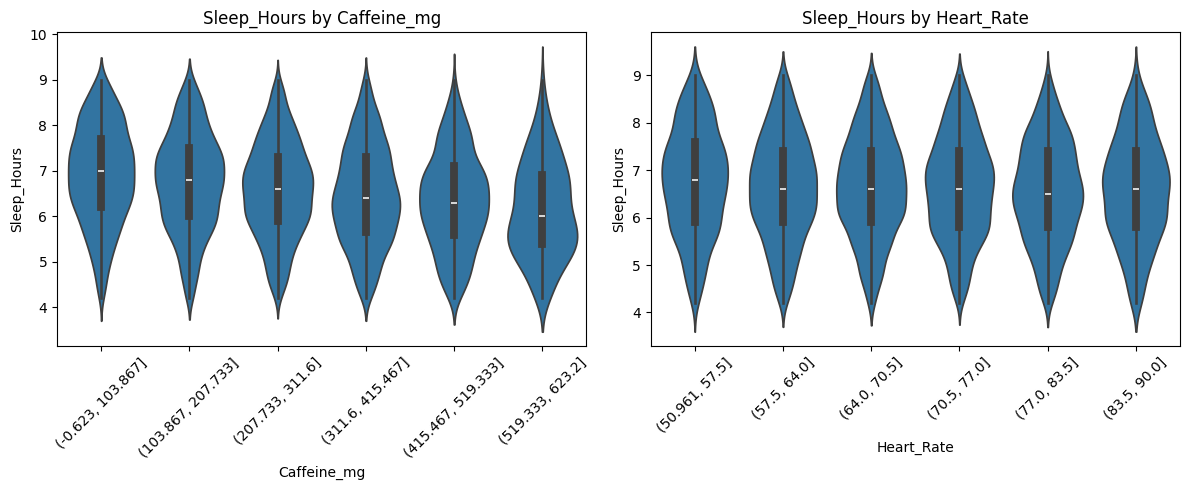

In [ ]:
quant_cols = ['Caffeine_mg', 'Heart_Rate']                   # Список количественных признаков

fig, axes = plt.subplots(1, 2, figsize=(12, 5))              # Создаём фигуру с двумя графиками рядом (1 строка, 2 столбца)

for i, col in enumerate(quant_cols):                         # Запускаем цикл по списку количественных признаков, enumerate возвращает одновременно:
                                                             #   i — номер по порядку (0, 1)
                                                             #   col — название текущего признака ('Caffeine_mg', 'Heart_Rate')
    sns.violinplot(data=df_outliers_clean,
                   x=pd.cut(df_outliers_clean[col], bins=6), # Разбиваем количественный признак на 6 групп (бинов)
                   y='Sleep_Hours',
                   ax=axes[i])                               # Помещаем график в i-ю позицию (0 или 1)
    axes[i].set_title(f'Sleep_Hours by {col}')               # Добавляем заголовок к текущему графику
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Sleep_Hours')
    axes[i].tick_params(axis='x', rotation=45)               # Поворачиваем подписи на оси X на 45 градусов для читаемости

                                           # Автоматически подгоняем расстояние между графиками
plt.tight_layout()

**Категориальные признаки**

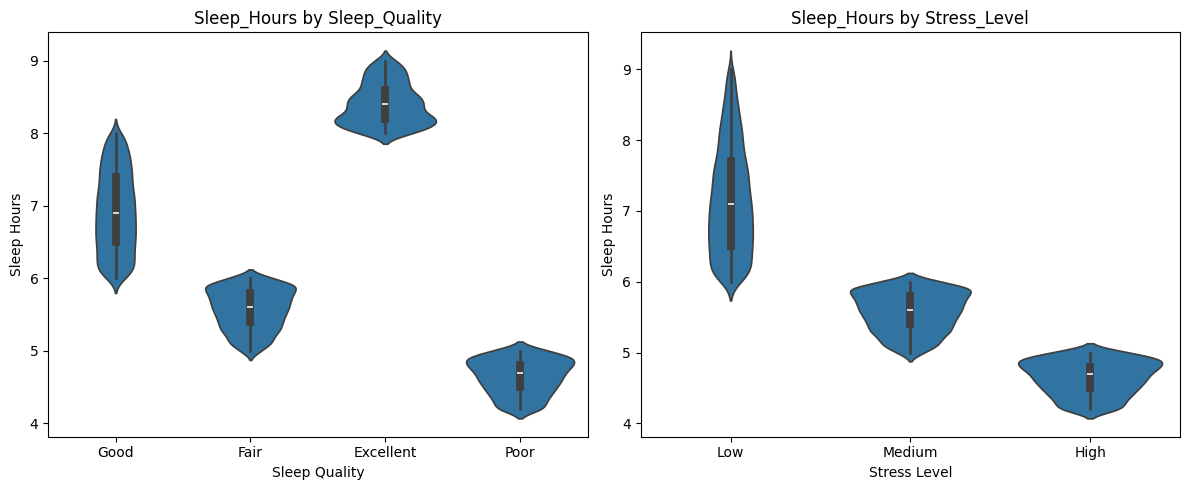

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.violinplot(data=df_outliers_clean, x='Sleep_Quality', y='Sleep_Hours', ax=axes[0])    # График для Sleep_Quality помещается в 0-ую позицию в строке
axes[0].set_title('Sleep_Hours by Sleep_Quality')
axes[0].set_xlabel('Sleep Quality')
axes[0].set_ylabel('Sleep Hours')

sns.violinplot(data=df_outliers_clean, x='Stress_Level', y='Sleep_Hours', ax=axes[1])     # График для Stress_Level помещается в 1-ую позицию в строке
axes[1].set_title('Sleep_Hours by Stress_Level')
axes[1].set_xlabel('Stress Level')
axes[1].set_ylabel('Sleep Hours')

plt.tight_layout()    # Автоматически подгоняем расстояние между графиками

## Выводы по скрипичным графикам (количественные признаки)

*   **Caffeine_mg (потребление кофеина):**
    *   Прослеживается слабая обратная зависимость.
    *   **Медианные значения по группам:**
        *   0–104 мг: ~7 часов
        *   105–208 мг: ~6.8 часов
        *   209–312 мг: ~6.5 часов
        *   313–415 мг: ~6.3 часов
        *   416–519 мг: ~6.1 часов
        *   520+ мг: ~5.9 часов
    *   **Разброс:** в группах с высоким потреблением (500+ мг) разброс увеличивается (4.0 – 9.0 часов), что говорит об индивидуальной чувствительности к кофеину.

*   **Heart_Rate (частота пульса):**
    *   Связь выражена слабее, чем с кофеином.
    *   **Медианные значения по группам:**
        *   51–58 уд/мин: ~6.8 часов
        *   59–64 уд/мин: ~6.6 часов
        *   65–71 уд/мин: ~6.5 часов
        *   72–77 уд/мин: ~6.5 часов
        *   78–84 уд/мин: ~6.4 часов
        *   85+ уд/мин: ~6.6 часов
    *   **Разброс:** при пульсе выше 80 уд/мин разброс значений сна увеличивается (4.0 – 8.8 часов), что может быть связано с влиянием стресса или других факторов.

## Выводы по скрипичным графикам (категориальные признаки)


*   **Sleep_Quality (качество сна):**
    *   Наблюдается прямая зависимость: чем выше качество сна, тем больше его продолжительность.
    *   **Медианные значения:**
        *   Excellent: ~8.5 часов
        *   Good: ~6.9 часов
        *   Fair: ~5.6 часов
        *   Poor: ~4.7 часов
    *   **Разброс:**
        *   Excellent: 8.0 – 9.0 часов
        *   Good: 6.0 – 8.0 часов
        *   Fair: 5.0 – 6.0 часов
        *   Poor: 4.2 – 5.0 часов
    *   Наиболее широкий разброс в группе Good, это может означать, что люди с субъективно «хорошим» качеством сна имеют очень разную его продолжительность.

*   **Stress_Level (уровень стресса):**
    *   Наблюдается обратная зависимость: чем выше стресс, тем меньше часов сна.
    *   **Медианные значения:**
        *   Low: ~7.2 часов
        *   Medium: ~5.7 часов
        *   High: ~4.8 часов
    *   **Разброс:**
        *   Low: 6.0 – 9.0 часов
        *   Medium: 5.1 – 6.0 часов
        *   High: 4.3 – 5.0 часов
    *   В группе с низким уровнем стресса (Low) наблюдается наибольший разброс продолжительности сна. Это может означать, что при отсутствии стресса люди спят по-разному в зависимости от других факторов (возраст, активность, привычки). С ростом стресса разброс сужается, а значения смещаются в сторону меньшей продолжительности.

## Описательные статистики

##Для целевого признака:

In [ ]:
target = 'Sleep_Hours'
df_outliers_clean[target].describe()

,Sleep_Hours
count,8634.000000
mean,6.630056
std,1.084011
min,4.200000
25%,5.900000
50%,6.600000
75%,7.400000
max,9.000000


In [ ]:
target = 'Sleep_Hours'
pd.Series({
    'variance': df_outliers_clean[target].var(),
    'range': df_outliers_clean[target].max() - df_outliers_clean[target].min(),
    'IQR': df_outliers_clean[target].quantile(0.75)
           - df_outliers_clean[target].quantile(0.25),
    'median': df_outliers_clean[target].median(),
    'mode': df_outliers_clean[target].mode().iloc[0],
})

,0
variance,1.175081
range,4.800000
IQR,1.500000
median,6.600000
mode,6.700000


## Интерпретация описательной статистики целевого признака

* mean (среднее значение): в среднем продолжительность сна респондентов составляет 6,63 часа.
* std (стандартное отклонение): в среднем продолжительность сна отклоняется от среднего на 1,08 часа.
* min (минимальное значение): минимальная продолжительность сна в датасете — 4,2 часа.
* Q1 (первый квартиль): 25% респондентов спят менее 5,9 часов
* Медиана: 50% респондентов спят менее 6,6 часов, остальные 50% — больше.
* Q3 (третий квартиль): 25% респондентов спят более 7,4 часов.
* max (максимальное значение): максимальная продолжительность сна составляет 9 часов.
* variance (дисперсия): средний квадрат отклонения от средней продолжительности сна равна 1,18 (часа ^2).
* range (размах): разница между максимальным и минимальным значением продолжительности сна равна 4,8 часов.
* IQR (интерквартильный размах): центральная половина значений продолжительности сна имеет значение в интервале шириной 1,5 часа.
* mode (мода): наиболее часто встречающееся значение продолжительности сна — 6,7 часа.

##Для количественных предикторов:

In [ ]:
num_predictors = [
    'Caffeine_mg',
    'Heart_Rate',
    'Physical_Activity_Hours', 'Age'
]

df_outliers_clean[num_predictors].describe()

,Caffeine_mg,Heart_Rate,Physical_Activity_Hours,Age
count,8634.000000,8634.000000,8634.000000,8634.000000
mean,237.846271,70.487491,7.499386,34.860435
std,135.637012,8.845307,4.327163,11.031556
min,0.000000,51.000000,0.000000,18.000000
25%,139.025000,64.000000,3.700000,26.000000
50%,236.100000,71.000000,7.500000,34.000000
75%,333.000000,77.000000,11.200000,42.000000
max,623.200000,90.000000,15.000000,68.000000


In [ ]:
stats = {}
for col in num_predictors:
    stats[col] = pd.Series({
        'mode': df_outliers_clean[col].mode().iloc[0],
        'variance': df_outliers_clean[col].var(),
        'median': df_outliers_clean[col].median(),
        'range': df_outliers_clean[col].max() - df_outliers_clean[col].min(),
        'IQR': df_outliers_clean[col].quantile(0.75) - df_outliers_clean[col].quantile(0.25)})
pd.DataFrame(stats)

,Caffeine_mg,Heart_Rate,Physical_Activity_Hours,Age
mode,0.000000,70.000000,8.400000,18.000000
variance,18397.398921,78.239447,18.724335,121.695219
median,236.100000,71.000000,7.500000,34.000000
range,623.200000,39.000000,15.000000,50.000000
IQR,193.975000,13.000000,7.500000,16.000000


##Для категориальных предикторов:

In [ ]:
cat_predictors = [
    'Gender',
    'Sleep_Quality',
    'Stress_Level']

for col in cat_predictors:
    table= pd.DataFrame({                                                        # Создаём таблицу с частотами и процентами для текущего признака
            'count': df_outliers_clean[col].value_counts(),
            'percent': df_outliers_clean[col].value_counts(normalize=True).mul(100).round(2)})  # value_counts(normalize=True) — считает долю каждой категории (от 0 до 1)
                                                                                 # .mul(100) — умножает все доли на 100, переводя их в проценты

    table.loc['mode'] = [df_outliers_clean[col].mode().iloc[0], '-']             # Добавляем в таблицу строку с mode
    display(table)                                                               # Выводим готовую таблицу

,count,percent
Gender,,
Female,4301,49.81
Male,4136,47.9
Other,197,2.28
mode,Female,-


,count,percent
Sleep_Quality,,
Good,5090,58.95
Fair,1865,21.6
Excellent,1010,11.7
Poor,669,7.75
mode,Good,-


,count,percent
Stress_Level,,
Low,6100,70.65
Medium,1865,21.6
High,669,7.75
mode,Low,-


In [ ]:
freq = df_outliers_clean['Occupation'].value_counts()   # Анализ признака Occupation: получаем частоты

occupation_table = pd.DataFrame({       # Создаём таблицу с частотами и процентами
    'count': freq,
    'percent': (freq / len(df_outliers_clean) * 100).round(2)
})

occupation_table.loc['nunique'] = [df_outliers_clean['Occupation'].nunique(), '-']     # Добавляем строки со статистиками
occupation_table.loc['mode'] = [df_outliers_clean['Occupation'].mode().iloc[0], '-']
occupation_table.loc['total'] = [len(df_outliers_clean), '100.00']

display(occupation_table)

,count,percent
Occupation,,
Office,1801,20.86
Other,1776,20.57
Service,1686,19.53
Student,1686,19.53
Healthcare,1685,19.52
nunique,5,-
mode,Office,-
total,8634,100.00


##Для категориальных бинарных предикторов:

In [ ]:
binary_stats = {}                                          # Создаём пустой словарь, где будем хранить статистики для каждого признака

for col in ['Smoking_True', 'Alcohol_Consumption_True']:

  true_count = df_outliers_clean[col].sum()

  binary_stats[col] = pd.Series({                          # Для каждого признака создаём Series с нужными статистиками и кладём её в словарь под ключом col (название признака)
        'mean': df_outliers_clean[col].mean().round(2),
        'mode': df_outliers_clean[col].mode().iloc[0],
        '%True': (true_count / len(df_outliers_clean) * 100).round(2),
        'count_True': true_count,
        'count_False': len(df_outliers_clean) - true_count
    })

pd.DataFrame(binary_stats)                                 # Преобразуем словарь в DataFrame: ключи словаря (названия признаков) становятся названиями колонок
                                                           # Индексы Series (mean, mode, %True, ...) становятся строками

,Smoking_True,Alcohol_Consumption_True
mean,0.20,0.30
mode,0.00,0.00
%True,19.82,30.28
count_True,1711.00,2614.00
count_False,6923.00,6020.00


## Интерпретация описательной статистики предикторов

## Количественные предикторы:

**Age (возраст)**

*  mean (среднее значение): в среднем, возраст респондентов составляет 34 года
*  std (стандартное отклонение): в среднем возраст откланяется от среднего на 11 лет
* min (минимальное значение): минимальный возраст в датасете - 18 лет
* Q1 (первый квартиль): 25% респондентов имеют возраст меньше 26 лет
* Медиана: 50% респондентов имеют возраст меньше 34 лет, остальные 50% - больше
* Q3 (третий квартиль): 25% респондентов имеют возраст больше 42 лет
* max (максимальное значение): максимальный возраст - 68 лет
* mode (мода): наиболее часто встречающееся значение возраста — 18 лет.
* variance (дисперсия): средний квадрат отклонения от среднего возраста составляет 121,69 (года ^2).
* range (размах): разница между максимальным и минимальным возрастом равна 50 лет.
* IQR (интерквартильный размах): центральная половина респондентов имеет возраст в интервале шириной 16 лет.

**Caffeine_mg (потребление кофеина)**

* mean (среднее значение): в среднем уровень потребления кофеина составляет 237,85 мг.
* std (стандартное отклонение): в среднем значение потребления кофеина отклоняется от среднего на 135,64 мг.
* min (минимальное значение): минимальное значение потребления кофеина в датасете — 0 мг.
* Q1 (первый квартиль): 25% респондентов потребляют менее 139,03 мг кофеина.
* Медиана: 50% респондентов потребляют менее 236,10 мг кофеина, остальные 50% — больше.
* Q3 (третий квартиль): 25% респондентов потребляют более 333,00 мг кофеина.
* max (максимальное значение): максимальное значение потребления кофеина составляет 623,20 мг.
* mode (мода): наиболее часто встречающееся значение потребления кофеина — 0 мг.
* variance (дисперсия): средний квадрат отклонения от среднего уровня потребления кофеина составляет 18397,39 (мг^2).
* range (размах): разница между максимальным и минимальным значением потребления кофеина равна 623,2 мг.
* IQR (интерквартильный размах): центральная половина значений потребления кофеина респондентами имеет значение в интервале шириной 193,98 мг.

**Heart_Rate (частота сердечных сокращений)**

* mean (среднее значение): в среднем частота сердечных сокращений составляет 70,49 уд/мин.
* std (стандартное отклонение): в среднем частота сердечных сокращений отклоняется от среднего на 8,85 уд/мин.
* min (минимальное значение): минимальная частота сердечных сокращений в датасете — 51 уд/мин.
* Q1 (первый квартиль): 25% респондентов имеют частоту сердечных сокращений ниже 64 уд/мин.
* Медиана: 50% респондентов имеют частоту сердечных сокращений ниже 71 уд/мин, остальные 50% — выше.
* Q3 (третий квартиль): 25% респондентов имеют частоту сердечных сокращений выше 77 уд/мин.
* max (максимальное значение): максимальная частота сердечных сокращений составляет 90 уд/мин.
* mode (мода): наиболее часто встречающееся значение частоты сердечных сокращений — 70 уд/мин.
* variance (дисперсия): средний квадрат отклонения от средней частоты сердечных сокращений составляет 78,24.
* range (размах): разница между максимальной и минимальной частотой сердечных сокращениц равна 39 уд/мин.
* IQR (интерквартильный размах): центральная половина значений частоты сердечных сокращений имеет значение в интервале шириной 13 уд/мин.

**Physical_Activity_Hours (часы физической активности)**

* mean (среднее значение): в среднем респонденты занимаются физической активностью 7,50 часа.
* std (стандартное отклонение): в среднем количество часов физической активности отклоняется от среднего на 4,33 часа.
* min (минимальное значение): минимальное количество часов физической активности в датасете — 0 часов.
* Q1 (первый квартиль): 25% респондентов занимаются физической активностью менее 3,7 часа.
* Медиана: 50% респондентов занимаются физической активностью менее 7,5 часа, остальные 50% — больше.
* Q3 (третий квартиль): 25% респондентов занимаются физической активностью более 11,2 часа.
* max (максимальное значение): максимальное количество часов физической активности составляет 15 часов.
* mode (мода): наиболее часто встречающееся значение физической активности составляет 8,4 часа.
* variance (дисперсия): средний квадрат отклонения от среднего количества часов физической активности равен 18,72 (часов ^2).
* range (размах): разница между максимальным и минимальным количеством часов физической активности составляет 15 часов.
* IQR (интерквартильный размах): центральная половина значений количества часов физической активности имеет значение в интервале 7,5 часов.

## Категориальные предикторы:

**Gender (пол)**

* Male: 4136 (47,9%)
* Female: 4301 (49,81%)
* Other: 197 (2,28%)
* mode: Female
* nunique: 3
* Вывод: доля мужчин и женщин практически равна в датасете, однако количество женщин немного больше.

**Sleep_Quality (качество сна)**

* Good: 5090 (58,95%)
* Fair: 1865 (21,6%)
* Excellent: 1010 (11,7%)
* Poor: 669 (7,75%)
* mode: Good
* nunique: 4
* Вывод: выборке преобладают респонденты с хорошим качеством сна. Значительно меньшая доля наблюдений приходится на категории «Fair» и «Excellent», при этом наименьшая доля участников характеризуется плохим качеством сна.

**Stress_Level (уровень стресса)**

* Low: 6100 (70,65%)
* Medium: 1865 (21,6%)
* High: 669 (7,75%)
* mode: Low
* nunique: 3
* Вывод: Большинство респондентов имеют низкий уровень стресса. Средний уровень стресса представлен существенно меньшей долей наблюдений, тогда как высокий уровень стресса встречается реже всего.

**Occupation (род деятельности)**

* Total = 8634 — общее количество респондентов
* Unique = 5 — в данных представлено 5 категорий профессий
* Mode = Office — самая часто встречающаяся профессия (20.86% выборки)
* Other (20.57%) — вторая по величине, включает профессии вне основных категорий
* Service, Student, Healthcare (19.5%) — представлены практически одинаково, разница минимальна

* Вывод: выборка хорошо сбалансирована по профессиональному составу — ни одна группа не доминирует. Это позволяет корректно сравнивать различные профессии при анализе влияния кофе на сон и делать обобщённые выводы.

## Категориальные бинарные предикторы:

**Smoking (курение)**

* mean = 0.20 — в среднем 20% респондентов курят (значение 1/True)
* mode = 0.00 — наиболее часто встречающееся значение — некурящие (0/False)
* %True = 19.82% — доля курящих от всей выборки
* count_True = 1711 — количество курящих респондентов
* count_False = 6923 — количество некурящих респондентов

* Вывод: В выборке значительно преобладают некурящие люди (около 80%), что может положительно влиять на показатели их сна и здоровья.

**Alcohol_Consumption (употребление алкоголя)**

* mean (среднее) = 0.30 — в среднем 30% респондентов употребляют алкоголь (значение 1/True)
* mode (мода) = 0.00 — наиболее часто встречающееся значение — неупотребляющие (0/False)
* %True = 30.28% — доля употребляющих алкоголь от всей выборки
* count_True = 2614 — количество употребляющих алкоголь
* count_False = 6020 — количество неупотребляющих алкоголь

* Вывод: Большинство респондентов (около 70%) не употребляют алкоголь. Доля употребляющих почти в 2.3 раза меньше, чем неупотребляющих, что может быть связано с особенностями выборки или культурными особенностями стран-участниц исследования.

##KT3

## Парная корреляция между целевой Sleep_Hours и предиктором Caffeine_mg

In [ ]:
corr_pred_with_target=df_outliers_clean['Sleep_Hours'].corr(df_outliers_clean['Caffeine_mg']).round(2)
corr_pred_with_target

np.float64(-0.18)

## Интерпретация парной корреляции

Между целевым признаком Sleep_Hours и предиктором Caffeine_mg существует слабая обратная корреляция, так как $r < 0$ и $|r| < 0.3$.

Можно предположить, что при увеличении среднесуточного потребления кофеина продолжительность сна снижается

## Корреляционная матрица, показывающая степень монотонной зависимости с целевой переменной

Мы построили корреляционную матрицу Спирмана, так как она подходит для порядковых переменных и не требует нормального распределения данных.

<Axes: >

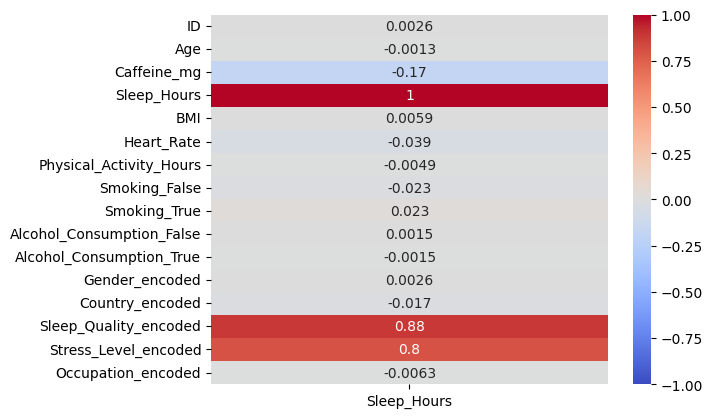

In [ ]:
corr_with_exam = df_outliers_clean.corr(method='spearman', numeric_only=True)[['Sleep_Hours']]
sns.heatmap(corr_with_exam, annot=True, vmin=-1, vmax=1, cmap='coolwarm')

## Топ-5 признаков c самой сильной связью с целевой переменной

+ Stress_Quality_encoded
+ Sleep_Level_encoded
+ Caffeine_mg
+ Heart_Rate
+ Smoking_True

##Словесное описание модели регрессии

Мы хотим построить модель множественной линейной регрессии, которая предсказывает продолжительность сна (Sleep_Hours) на основании уровня стресса (Stress_Level), качества сна (Sleep_Quality), потребления кофеина (Caffeine_mg), частоты пульса (Heart_Rate) и статуса курения (Smoking)

##Регрессия

###Деление выборки на тренировочную и тестовую

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X=df_outliers_clean[['Stress_Level_encoded', 'Sleep_Quality_encoded',
       'Caffeine_mg', 'Heart_Rate', 'Smoking_True']]
Y=df_outliers_clean['Sleep_Hours']

X_train, X_test, y_train, y_test = train_test_split(X, Y,
                                                    test_size=0.2,
                                                    random_state=42)

Нормализуем количественные признаки с помощью StandartScaler():

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
scaler = StandardScaler()    # Создаём объект scaler
X_train_scaled = scaler.fit_transform(X_train)   # Обучаем scaler на тренировочных данных и сразу преобразуем их
X_test_scaled = scaler.transform(X_test)   # Преобразуем тестовые данные

##Обучение модели регрессии на тренировочной выборке

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
model=LinearRegression().fit(X_train_scaled, y_train)

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
model.intercept_      # свободный коэффициент (w0)

np.float64(6.630244679310844)

In [ ]:
model.coef_    # коэффициенты независимых переменных (w1, w2, w3, w4, w5)

array([-0.18463631,  1.13988297, -0.03824458, -0.00595205,  0.00414092])

##Уравнение обученной модели

$\text{Sleep Hours} = 6.63 - 0.18 \times \text{Stress_Level_encoded} + 1.14 \times \text{Sleep_Quality_encoded} - 0.04 \times \text{Caffeine_mg} - 0.01 \times \text{Heart_Rate} + 0.004 \times \text{Smoking_True}$



+ **Свободный коэффициент** ($w_0$): После стандартизации нулевое значение признака соответствует среднему значению исходного признака, поэтому типичный респондент, у которого все остальные стандартизированные по StandartScaler() признаки равны нулю, имеет средние по выборке значения всех исходных предикторов, и его продолжительность сна равна среднему значению $6.63$ часа.

Поскольку количественные признаки были масштабированы с помощью StandardScaler,
их коэффициенты интерпретируются как изменение зависимой переменной
при увеличении признака на **одно стандартное отклонение**.
+ **Коэффициенты независимых переменных**:
  + Коэффициент **Stress_Level_encoded** ($w_1$):
  При увеличении уровня стресса на одно стандартное отклонение
  ожидаемая продолжительность сна уменьшается на 0.18 часа.
  + Коэффициент **Sleep_Quality_encoded** ($w_2$): При повышении субъективной оценки качества сна на одно стандартное отклонение продолжительность сна увеличивается на 1.14 часа
  + Коэффициент **Caffeine_mg** ($w_3$): При увеличенит потребления кофеина на одно стандартное отклонение продолжительность сна снижается на 0.04 часа
  + Коэффициент **Heart_Rate** ($w_4$): При увеличении частоты сердечных сокращений на одно стандартное отклонение продолжительность сна снижается на 0.01 часа
  + Коэффициент **Smoking_True** ($w_5$):Если человек курильщик (1; Smoking_True), то продолжительность сна увеличивается на 0.004 часа

##Метрики качества модели

In [ ]:
y_pred = model.predict(X_test_scaled)

MSE1 = mean_squared_error(y_test, y_pred)
MAE1 = mean_absolute_error(y_test, y_pred)
R2_1 = r2_score(y_test, y_pred)

(MSE1, MAE1, R2_1)

(0.20401940562585177, 0.3645705345075572, 0.8230717650100333)

##Интерпретация метрик качества обученной модели

+ $MSE$: В среднем модель ошибается в предсказании продолжительности сна на $0.2 \text{ часа}^2$

+ $MAE$: В среднем модель ошибается в предсказании продолжительности сна на $0.36 \text{ часа}$

+ $R^2$: Модель объясняет 82% вариаций продолжительности сна. Значение R² указывает на то, что модель достаточно хорошо описывает зависимость между признаками и продолжительностью сна.

##Тестирование гипотез

###Одновыборочный Z-тест

Проведем одновыборочный Z-тест для целевого признака Sleep_Hours.
Для начала проверим, удовлетворяет ли признак предпосылкам:
+ признак нормально распределен
+ известна дисперсия генеральной совокупности
+ количество наблюдений не менее 30

Чтобы проверить, имеет ли признак Sleep_Hours (X) нормальное распределение, проведем тест Шапиро-Уилка:
Формулируем гипотезы:

$H_0: X \sim N(\mu, \sigma^2)$

$H_1: X \not\sim N(\mu, \sigma^2)$



In [ ]:
from scipy.stats import shapiro
res = shapiro(df_outliers_clean['Sleep_Hours'])
res[1]         # p_value

/usr/local/lib/python3.12/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 8634.
  res = hypotest_fun_out(*samples, **kwds)


np.float64(4.173590120894122e-24)

**Вывод**: p-value меньше 1%, поэтому на любом адекватном уровне значимости $H_0$ отвергается, что означает, что признак Sleep_Hours не имеет нормального распределения, а значит мы не можем провести одновыборочный Z-тест, так как не выполнена предпосылка о нормальном распределении признака

Проведем тест Шапиро-Уилка для остальных количественных признаков, чтобы понять, есть ли среди них те, которые удовлетворяют предпосылке о нормальном распределении

Проведем тест Шапиро-Уилка для следующих количественных признаков:
+ Caffeine_mg
+ Age
+ BMI
+ Heart_Rate
+ Physical_Activity_Hours

Формулируем гипотезы:

$H_0: X \sim N(\mu, \sigma^2)$

$H_1: X \not\sim N(\mu, \sigma^2)$

In [ ]:
from scipy.stats import shapiro
res = shapiro(df_outliers_clean['Caffeine_mg'])   # Тест Шапиро-Уилка для признака Caffeine_mg
res[1]

np.float64(1.7467474574033295e-28)

In [ ]:
from scipy.stats import shapiro
res = shapiro(df_outliers_clean['Age'])   # Тест Шапиро-Уилка для признака Age
res[1]

np.float64(1.570455384423145e-37)

In [ ]:
from scipy.stats import shapiro
res = shapiro(df_outliers_clean['BMI'])   # Тест Шапиро-Уилка для признака BMI
res[1]

np.float64(1.105092780635257e-22)

In [ ]:
from scipy.stats import shapiro
res = shapiro(df_outliers_clean['Heart_Rate'])   # Тест Шапиро-Уилка для признака Heart_Rate
res[1]

np.float64(3.936437048696169e-24)

In [ ]:
from scipy.stats import shapiro
res = shapiro(df_outliers_clean['Physical_Activity_Hours'])   # Тест Шапиро-Уилка для признака Physical_Activity_Hours
res[1]


np.float64(1.6345643193473835e-45)

**Вывод**: p-value во всех случаях меньше 1%, поэтому на любом адекватном уровне значимости $H_0$ отвергается, что означает, что признаки Caffeine_mg, Age, BMI, Heart_Rate и Physical_Activity_Hours не имеют нормального распределения, а значит мы не можем провести одновыборочный Z-тест, так как не выполнена предпосылка о нормальном распределении признаков

###Одновыборочный t-тест

**Предпосылка одновыборочного t-теста**:

• признак нормально распределен (или имеется большая выборка)

Несмотря на то, что тест Шапиро-Уилка показал отклонение от нормального распределения(p-value < 0.001), что связано с высокой чувствительностью теста  при большом объеме выборки (n = 8634), мы можем использовать одновыборочный t-тест при условии большой выборки.

**Словесная формулировка проводимого теста:** Средняя продолжительность сна в признаке Sleep_Hours равна 6.63 часам. Мы хотим проверить гипотезу о том, что средняя продолжительность сна в исследуемой выборке меньше рекомендуемой нормы (7 часов)

**Математическая формализация гипотез:**

$H_0$: $\mu = 7$

$H_1$: $\mu < 7$

In [ ]:
from scipy import stats
stats.ttest_1samp(df_outliers_clean['Sleep_Hours'], # выборка
                  popmean=7, # ожидаемое среднее
                  alternative='less')

TtestResult(statistic=np.float64(-31.71090698351128), pvalue=np.float64(3.7382237395177325e-209), df=np.int64(8633))

### Интерпретация результата

Полученное p-value значительно меньше любого адекватного уровня значимости α (1%, 5% или 10%), поэтому мы **отвергаем нулевую гипотезу** $H_0$ и принимаем альтернативную гипотезу $H_1$.

Это означает, что средняя продолжительность сна в исследуемой выборке (6.63 часа) ниже рекомендуемой нормы.

###Парный t-тест

**Предпосылки парного t-теста**:
+ выборки связаны
+ разность выборок нормально распределена

В нашем случае отсутствуют связанные выборки, из-за чего проведение парного t-теста невозможно

###Двухвыборочный t-тест

**Предпосылки двухвыборочного t-теста**:
+ выборки не связаны
+ обе выборки имеют нормальное распределение
+ дисперсии выборок примерно равны

Однако мы уже провели тест Шапиро-Уилка для всех количественных признаков и увидели, что ни один из них не имеет нормальное распределение, а значит двухвыборочный t-тест мы провести также не можем

###Тест Манна-Уитни (U-тест)

**Предпосылки теста Манна-Уитни**:
+ выборки не связаны
+ похожая форма распределения обоих выборок
(скошены в одну сторону, имеют схожую
"вершину")
+ не требует нормальности
+ не требуется одинаковых дисперсий в обеих группах

**Словесная формулировка проводимого теста:**

Мы хотим проверить гипотезу о том, что продолжительность сна у людей, употребляющих кофеин (Caffeine\_mg > 0), не отличается от продолжительности сна у людей, не употребляющих кофеин (Caffeine\_mg = 0).

**Математическая формализация гипотез:**

$H_0$: Продолжительность сна у потребителей кофеина не отличается от продолжительности сна у непотребителей кофеина

$H_A$: Продолжительность сна у потребителей кофеина отличается от продолжительности сна у непотребителей кофеина

 Сначала проверим форму распределения в двух группах:

Text(0.5, 1.0, 'Непотребители кофе')

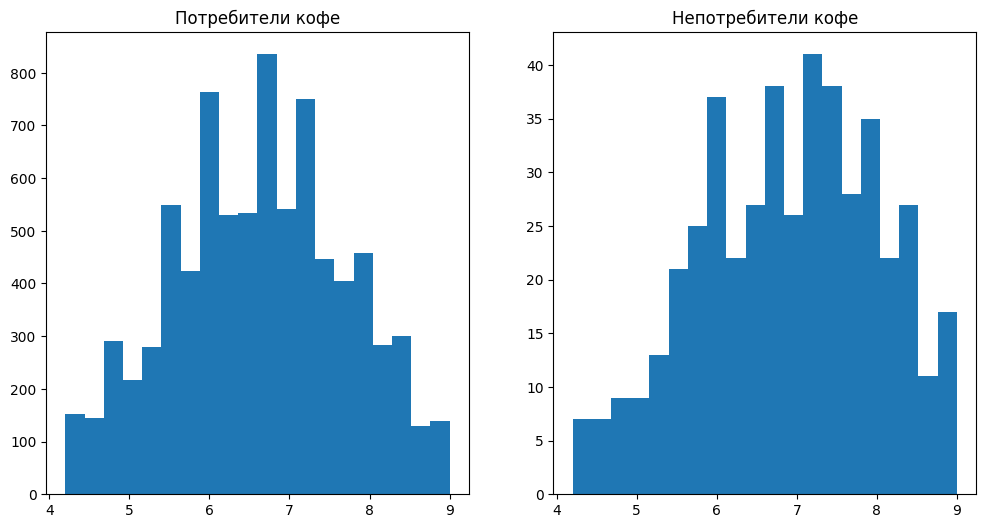

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12,6))

ax[0].hist(df_outliers_clean[df_outliers_clean['Caffeine_mg']>0]['Sleep_Hours'], bins=20)
ax[0].set_title('Потребители кофе')

ax[1].hist(df_outliers_clean[df_outliers_clean['Caffeine_mg']==0]['Sleep_Hours'], bins=20)
ax[1].set_title('Непотребители кофе')

На основе гистограмм можно сделать вывод, что распределения имеют схожую форму

In [ ]:
from scipy.stats import mannwhitneyu

statistic, p_value = mannwhitneyu(df_outliers_clean[df_outliers_clean['Caffeine_mg']>0]['Sleep_Hours'],
                                  df_outliers_clean[df_outliers_clean['Caffeine_mg']==0]['Sleep_Hours'],
                                  alternative='two-sided')
statistic, p_value

(np.float64(1611308.5), np.float64(2.3693692605160638e-07))

### Интерпретация результата

Полученное p-value значительно меньше любого адекватного уровня значимости α (1%, 5% или 10%), поэтому мы **отвергаем нулевую гипотезу** $H_0$ и принимаем альтернативную гипотезу $H_A$.

Это означает, что **существует значимое различие в продолжительности сна между потребителями и непотребителями кофеина**.


##Z-тест для одной пропорции

**Предпосылки теста:**

- наблюдения независимы
- переменная является бинарной
- размер выборки достаточен для нормального приближения:
  
$$
np_0 \ge 5 \quad \text{и} \quad n(1-p_0) \ge 5
$$


**Словесная формулировка проводимого теста:**

Мы хотим проверить гипотезу о том, отличается ли доля респондентов, употребляющих алкоголь, от 50%.

**Математическая формализация гипотез:**
$$
H_0: p = 0.5
$$

$$
H_A: p \ne 0.5
$$

In [ ]:
from statsmodels.stats.proportion import proportions_ztest

successes = df_outliers_clean['Alcohol_Consumption_True'].sum()   # число употребляющих алкоголь
n = len(df_outliers_clean)                                        # общий размер выборки

stat, p_value = proportions_ztest(successes, n, value=0.5)

stat, p_value


(np.float64(-39.89051404817329), np.float64(0.0))

### Интерпретация результата
Полученное p-value значительно меньше любого стандартного уровня значимости, поэтому
мы отвергаем нулевую гипотезу.

Это означает, что доля респондентов, употребляющих алкоголь,
статистически значимо отличается от 50%.

##Z-тест для пропорций (для двух пропорций)

**Предпосылки теста:**
- наблюдения независимы
- данные являются бинарными
- размер выборки достаточен для нормального приближения для каждой из групп:
  
$$
np \ge 5 \quad \text{и} \quad n(1-p) \ge 5
$$


**Словесная формулировка проводимого теста:**

Мы хотим проверить гипотезу о том, отличается ли доля курящих среди мужчин и женщин.

**Математическая формализация гипотез:**

$H_0$: доля курящих среди мужчин и женщин одинакова

$p_1 = p_2$

$H_A$: доли различаются

$p_1 \ne p_2$

In [ ]:
from statsmodels.stats.proportion import proportions_ztest

male_smokers = df_outliers_clean[df_outliers_clean['Gender']=='Male']['Smoking_True'].sum()
female_smokers = df_outliers_clean[df_outliers_clean['Gender']=='Female']['Smoking_True'].sum()

male_total = (df_outliers_clean['Gender']=='Male').sum()
female_total = (df_outliers_clean['Gender']=='Female').sum()

stat, p_value = proportions_ztest(
    [male_smokers, female_smokers],
    [male_total, female_total]
)

stat, p_value


(np.float64(-1.9155579517693), np.float64(0.05542138604026623))

### Интерпретация результата
Полученное значение p-value равно 0.0554. Поскольку

$$
p\text{-value} > \alpha = 0.05,
$$

у нас нет оснований отвергнуть нулевую гипотезу $H_0$ на уровне значимости 5%.

Следовательно, на уровне значимости 5% статистически значимые различия
между долями курящих среди мужчин и женщин не обнаружены.

При этом на уровне значимости 10% нулевая гипотеза отвергается,
что может указывать на возможное различие долей курящих между
мужчинами и женщинами, однако этот результат является менее
надежным.

## Критерий χ² (тест на независимость)

**Предпосылки теста:**
- наблюдения независимы (каждое наблюдение относится только к одной ячейке таблицы)
- переменные являются категориальными
- каждое ожидаемое значение в таблице сопряженности обычно должно быть ≥5.


**Словесная формулировка теста:**

Мы хотим проверить гипотезу о том, связан ли тип занятости с качеством сна.

**Математическая формализация гипотез:**

$H_0$: тип занятости и качество сна независимы

$H_A$: тип занятости и качество сна связаны

In [ ]:
from scipy import stats
gb = df_outliers_clean[['Occupation', 'Sleep_Quality']].value_counts().unstack()  #таблица сопряженности
gb


Sleep_Quality,Excellent,Fair,Good,Poor
Occupation,,,,
Healthcare,202,357,1000,126
Office,215,379,1054,153
Other,210,394,1036,136
Service,204,393,952,137
Student,179,342,1048,117


In [ ]:
# рассчитываем χ² статистику
result = stats.chi2_contingency(gb.values)
print(result)  # возвращает (χ², p-value, df, expected)

print("p > 0.10:", result.pvalue > 0.10)
print("p > 0.05:", result.pvalue > 0.05)
print("p > 0.01:", result.pvalue > 0.01)

Chi2ContingencyResult(statistic=np.float64(14.589574390249384), pvalue=np.float64(0.26465205618276105), dof=12, expected_freq=array([[ 197.11026176,  363.97092889,  993.35765578,  130.56115358],
       [ 210.67987028,  389.02768126, 1061.74310864,  139.54933982],
       [ 207.75538568,  383.62751911, 1047.00486449,  137.61223072],
       [ 197.22724114,  364.18693537,  993.94718555,  130.63863794],
       [ 197.22724114,  364.18693537,  993.94718555,  130.63863794]]))
p > 0.10: True
p > 0.05: True
p > 0.01: True


### Интерпретация результата
По результатам χ²-теста получено p-value = 0.265.

Так как p-value больше стандартных уровней значимости,
мы не отвергаем нулевую гипотезу.

Следовательно, на основе имеющихся данных нельзя утверждать,
что существует статистически значимая связь между типом занятости и качеством сна.